# Semana 2 · Entregable: tokens por idioma y variabilidad de la respuesta

**Parte 1.** Cuántos tokens cuesta el mismo texto en español y en inglés, con tres tokenizadores.
**Parte 2.** Cuánto varía la respuesta según `temperature` y `top_p`, con intervalos de confianza y varias corridas.

Ejecutar desde la raíz del repo o desde `semana-02/`. Para el conteo oficial de Claude necesitas `ANTHROPIC_API_KEY` en el entorno; sin ella, la celda usa una estimación y lo indica en la tabla.

In [1]:
from pathlib import Path
import csv
import os
import statistics

import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path(".").resolve()
CARPETA = RAIZ / "semana-02" if (RAIZ / "semana-02").exists() else RAIZ
print("carpeta de trabajo:", CARPETA)

carpeta de trabajo: /Users/manuelcorona/AI-projects-llm-internals/semana-02


## Parte 1 · Tokens por idioma

El mismo texto (política de reorden de inventario) en español e inglés. Cada tokenizador cuenta por separado; el costo solo aplica a Claude, con $2 USD por millón de tokens de entrada.

In [2]:
import tiktoken
from transformers import AutoTokenizer
from anthropic import Anthropic

ES = (CARPETA / "texto_es.txt").read_text(encoding="utf-8")
EN = (CARPETA / "texto_en.txt").read_text(encoding="utf-8")
PRECIO_USD_POR_MTOK = 2.0  # claude-sonnet-5-5, tokens de entrada

enc = tiktoken.get_encoding("o200k_base")
filas = [{"tokenizador": "tiktoken o200k_base", "ES": len(enc.encode(ES)),
          "EN": len(enc.encode(EN)), "método": "exacto"}]

qtok = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-7B-Instruct")
filas.append({"tokenizador": "Qwen2.5", "ES": len(qtok.encode(ES)),
              "EN": len(qtok.encode(EN)), "método": "exacto"})

if os.getenv("ANTHROPIC_API_KEY"):
    client = Anthropic()

    def contar(texto):
        return client.messages.count_tokens(
            model="claude-sonnet-5-5",
            messages=[{"role": "user", "content": texto}],
        ).input_tokens

    overhead = contar("a") - 1  # la letra "a" pesa 1 token; el resto es formato
    filas.append({"tokenizador": "Claude (sonnet-5-5)", "ES": contar(ES) - overhead,
                  "EN": contar(EN) - overhead, "método": f"oficial API, sin {overhead} tokens de formato"})
else:
    filas.append({"tokenizador": "Claude (sonnet-5-5)", "ES": len(enc.encode(ES)),
                  "EN": len(enc.encode(EN)), "método": "ESTIMACIÓN con o200k (sin clave API)"})

df_tokens = pd.DataFrame(filas)
df_tokens["ES/EN"] = (df_tokens.ES / df_tokens.EN).round(2)
df_tokens["ES extra"] = ((df_tokens.ES - df_tokens.EN) / df_tokens.EN * 100).round(0).astype(int).astype(str) + " %"

def costo(row, col):
    return round(row[col] / 1e6 * PRECIO_USD_POR_MTOK, 6) if row["tokenizador"].startswith("Claude") else None

df_tokens["costo ES USD"] = df_tokens.apply(lambda r: costo(r, "ES"), axis=1)
df_tokens["costo EN USD"] = df_tokens.apply(lambda r: costo(r, "EN"), axis=1)
df_tokens

ANTHROPIC_API_KEY is set and takes precedence over the SDK's profile / federation auto-discovery; unset ANTHROPIC_API_KEY to use the auto-discovered credential.


,tokenizador,ES,EN,método,ES/EN,ES extra,costo ES USD,costo EN USD
0,tiktoken o200k_base,280,246,exacto,1.14,14 %,NaN,NaN
1,Qwen2.5,321,246,exacto,1.30,30 %,NaN,NaN
2,Claude (sonnet-5-5),503,371,"oficial API, sin 8 tokens de formato",1.36,36 %,0.001006,0.000742


## Parte 2 · Variabilidad de la respuesta

Para cada valor de `temperature` (con `top_p` = 1.0) y de `top_p` (con `temperature` = 1.0) se piden N respuestas al mismo prompt. La variabilidad de cada respuesta es 1 − su similitud Jaccard promedio contra las demás (0 = todas iguales).

Cada corrida vive en su carpeta dentro de `corridas/`. El notebook promedia todas las corridas y muestra cada una por separado, para ver qué tanto cambia el resultado de una ejecución a otra.

In [3]:
def jaccard(a, b):
    A, B = set(a.lower().split()), set(b.lower().split())
    return len(A & B) / len(A | B) if A | B else 1.0

def cifras(textos):
    n = len(textos)
    return [1 - statistics.mean(jaccard(textos[i], textos[j]) for j in range(n) if j != i)
            for i in range(n)]

registros = []
for ruta in sorted((CARPETA / "corridas").glob("*/variabilidad_respuestas.csv")):
    grupos = {}
    for r in csv.DictReader(open(ruta, encoding="utf-8")):
        grupos.setdefault((r["barrido"], float(r["valor"])), []).append((int(r["corrida"]), r["respuesta"]))
    for (barrido, valor), lista in grupos.items():
        textos = [t for _, t in sorted(lista)]
        for c in cifras(textos):
            registros.append((ruta.parent.name, barrido, valor, c))

dfv = pd.DataFrame(registros, columns=["corrida", "barrido", "valor", "cifra"])
print("corridas encontradas:", sorted(dfv.corrida.unique()))

# Promedio de todas las corridas, con IC 95 % (aprox. normal)
filas_r = []
for (barrido, valor), g in dfv.groupby(["barrido", "valor"]):
    x = g.cifra
    ee = x.std() / len(x) ** 0.5
    filas_r.append({"barrido": barrido, "valor": valor, "n": len(x), "media": x.mean(),
                    "IC95_inf": x.mean() - 1.96 * ee, "IC95_sup": x.mean() + 1.96 * ee})
resumen = pd.DataFrame(filas_r)

# Media por corrida, para ver la variación entre ejecuciones
por_corrida = dfv.groupby(["corrida", "barrido", "valor"])["cifra"].mean().reset_index()
resumen

corridas encontradas: ['run1', 'run2', 'run3']


,barrido,valor,n,media,IC95_inf,IC95_sup
0,temperature,0.0,60,0.050135,0.024334,0.075936
1,temperature,0.7,60,0.622836,0.608259,0.637412
2,temperature,1.0,60,0.706672,0.684546,0.728797
3,top_p,0.5,60,0.533757,0.527130,0.540385
4,top_p,0.9,60,0.660532,0.642730,0.678334
5,top_p,1.0,60,0.668863,0.653521,0.684206


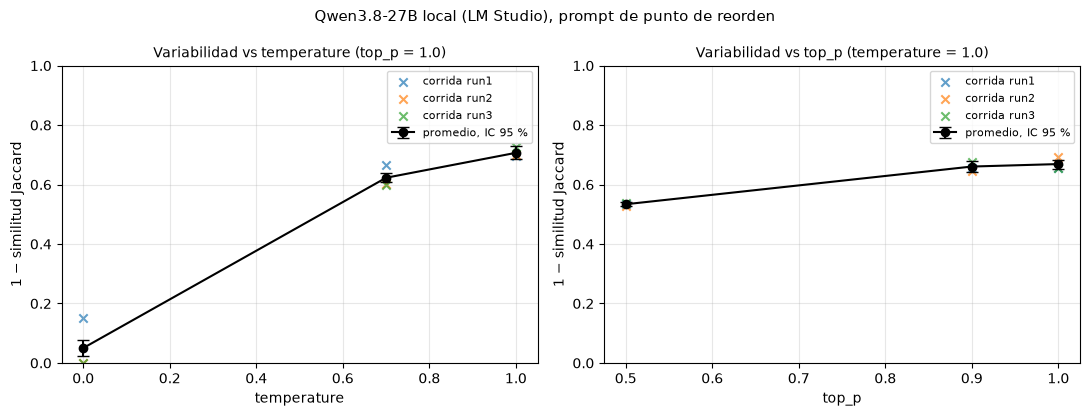

In [4]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.2))
titulos = {"temperature": "Variabilidad vs temperature (top_p = 1.0)",
           "top_p": "Variabilidad vs top_p (temperature = 1.0)"}

for ax, barrido in zip(ejes, ["temperature", "top_p"]):
    sub = resumen[resumen.barrido == barrido].sort_values("valor")
    ax.errorbar(sub.valor, sub.media,
                yerr=[sub.media - sub.IC95_inf, sub.IC95_sup - sub.media],
                marker="o", capsize=4, color="black", label="promedio, IC 95 %")
    for corrida, g in por_corrida[por_corrida.barrido == barrido].groupby("corrida"):
        ax.scatter(g.valor, g.cifra, marker="x", alpha=0.7, label=f"corrida {corrida}")
    ax.set_title(titulos[barrido], fontsize=10)
    ax.set_xlabel(barrido)
    ax.set_ylabel("1 − similitud Jaccard")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

fig.suptitle("Qwen3.8-27B local (LM Studio), prompt de punto de reorden", fontsize=11)
fig.tight_layout()
fig.savefig(CARPETA / "variabilidad_entregable.png", dpi=150)
plt.show()

## Conclusiones

Completar después de la última corrida. Lo que ya está sostenido por varias corridas:

- La variabilidad sube con `temperature`. A 0.0 no es cero: en la corrida guardada da 0.150, y en la corrida que pegaste da 0.068. Con 0.7 y 1.0 la respuesta cambia de forma clara.
- La variabilidad sube con `top_p` en el sentido esperado, pero la diferencia entre 0.9 y 1.0 no es estable entre corridas.

Para el conteo de tokens, las conclusiones salen de la tabla de la Parte 1 (el texto en español cuesta más tokens que el mismo texto en inglés en los tres tokenizadores).

## Limitaciones

- Jaccard mide variación de palabras, no de significado. Dos respuestas con el mismo contenido y distinta redacción puntúan como diferentes.
- Un solo prompt y un solo modelo local. Los resultados no se generalizan a otros modelos ni a otros prompts sin repetir el experimento.
- Los modelos de Claude (Sonnet 5.5, Opus 5.5, Fable 5.1) no aceptan `temperature` como parámetro libre, así que el barrido se hizo con Qwen local. Haiku 5.5 solo acepta `temperature` = 1 y `top_p` = 0.99.
- Anthropic no expone logprobs en la Messages API, y LM Studio no devuelve logprobs en su endpoint. Las probabilidades por token se calcularon con `mlx-lm` sobre el mismo modelo.
- La entropía por token se midió con una respuesta por semilla; el promedio con 20 semillas está en `entropia_multisemilla.csv`.